## 🔧  **SETUP**

In [3]:
# Set seed for reproducibility
SEED = 100

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch version: 2.9.1+cpu
Device: cpu


In [5]:
# ==========================================
# 🔧 CONFIGURAZIONE AUTOMATICA (LOCALE VS KAGGLE)
# ==========================================
def get_paths():
    """Rileva l'ambiente e restituisce i percorsi corretti."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Ambiente rilevato: KAGGLE")
        input_dir = Path('/kaggle/input/datasetnumpy/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Ambiente rilevato: LOCALE")
        # Percorso locale relativo al file del progetto
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


💻 Ambiente rilevato: LOCALE
Input directory: ..\data\archive
Output directory: ..\data\output


### ⚙️ **Libraries Import**

## ⏳ **Data Loading**

In [7]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE)
train_images = np.load(INPUT_DIR /"train_images.npy")
train_masks = np.load(INPUT_DIR/'train_masks.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')


print("Dati caricati dal dataset!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")

Dati caricati dal dataset!
Train images shape: (1252, 224, 224, 3)
Train masks shape: (1252, 224, 224, 1)


## 🖼️ DATA VISUALIZATION

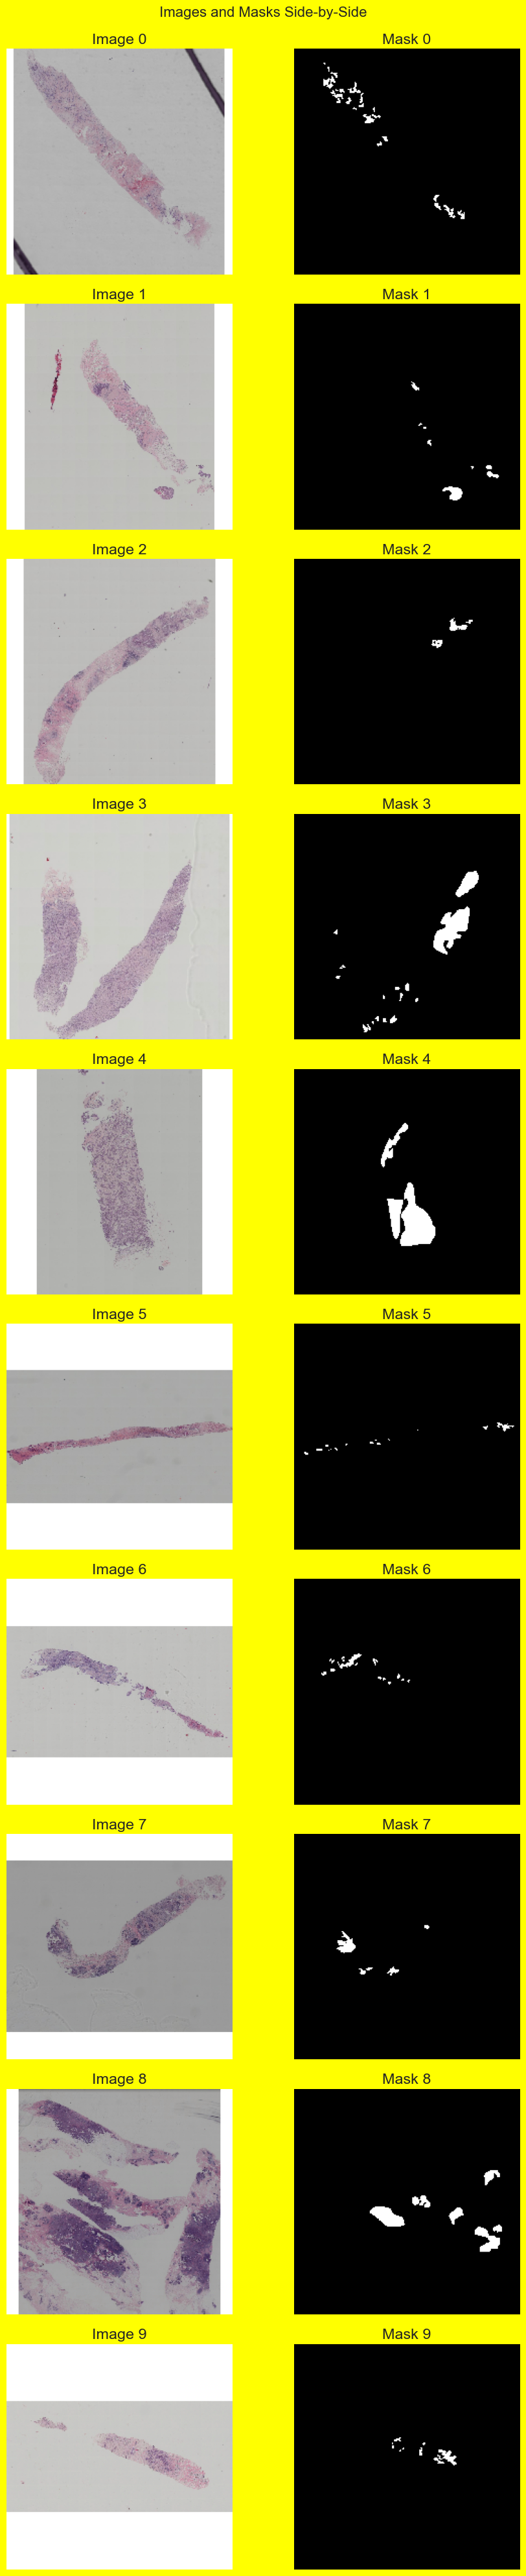

In [8]:
# Number of images to displayyy
num_img = 10
# Display side-by-side comparison (image + mask)
fig, axes = plt.subplots(num_img, 2, figsize=(10, 4*num_img))
fig.patch.set_facecolor('yellow')  # Sfondo giallo per la figura intera
fig.suptitle('Images and Masks Side-by-Side', fontsize=16, y=0.995)
for i in range(num_img):
    # Image on left
    axes[i, 0].imshow(np.clip(train_images[i], 0, 1))
    axes[i, 0].set_title(f'Image {i}')
    axes[i, 0].axis('off')
    axes[i, 0].set_facecolor('yellow')  # Sfondo giallo per i subplot
    
    # Mask on right
    axes[i, 1].imshow(train_masks[i].squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {i}')
    axes[i, 1].axis('off')
    axes[i, 1].set_facecolor('yellow')  # Sfondo giallo per i subplot
plt.tight_layout()
plt.show()